In [110]:
import librosa
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

In [111]:
TRAIN_PATH = "train_data.npz"
SAMPLE_RATE = 16000
data = np.load(TRAIN_PATH)

def extract_features(audio):
    mfcc = librosa.feature.mfcc(y=audio, sr=SAMPLE_RATE)
    chroma = librosa.feature.chroma_stft(y=audio, sr=SAMPLE_RATE)
    return np.concatenate([mfcc.mean(axis=1), mfcc.std(axis=1), chroma.mean(axis=1), chroma.std(axis=1)])

train_features = np.stack([extract_features(audio) for audio in data["audio"]])
scaler = MinMaxScaler().fit(train_features)
X = scaler.transform(train_features)

X.shape

(600, 64)

In [112]:
TEST_PATH = "test_data.npz"

test_data = np.load(TEST_PATH)
test_features = np.stack([extract_features(audio) for audio in test_data["audio"]])
X_final = scaler.transform(test_features)

X_final.shape

(300, 64)

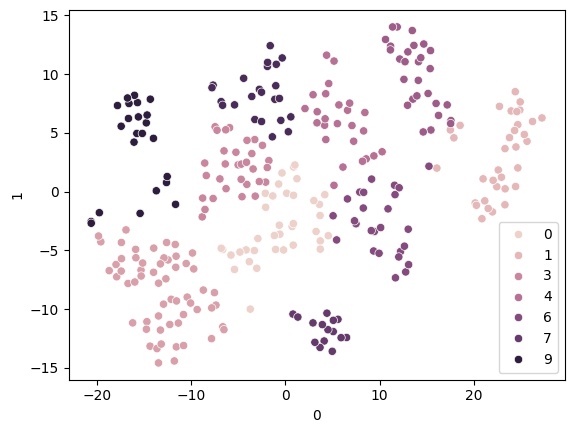

In [113]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans

decom = TSNE(n_components=2)
X_red = pd.DataFrame(decom.fit_transform(X_final))

model = KMeans(n_clusters=10)
labels = model.fit_predict(X_red)

sns.scatterplot(x=X_red[0], y=X_red[1], hue=labels)
plt.show()

In [114]:
answer_df = pd.DataFrame({"id": test_data["audio_id"], "answer": labels + 1})
answer_df

,id,answer
0,0,8
1,1,2
2,2,1
3,3,7
4,4,3
...,...,...
295,295,8
296,296,4
297,297,3
298,298,1


In [115]:
answer_df.answer.value_counts()

answer
3     58
1     37
2     34
4     31
6     28
7     26
5     25
10    23
9     23
8     15
Name: count, dtype: int64

In [116]:
answer_df.to_csv("submission.csv", index=False)